<a href="https://colab.research.google.com/github/Iucasoa/Sistemas-Inteligentes/blob/main/problema3-knn/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problema 3: Classificação de Qualidade de Vinhos Utilizando $k$-NN

Neste trabalho vamos construir um classificador $k$-NN que atribui cada vinho tinto a uma de três categorias de qualidade (ruim, médio e bom) a partir de 11 atributos físico-químicos, utilizando o arquivo `winequality-red.csv` do *dataset* **Wine Quality**. O fluxo segue o notebook de $k$-NN da disciplina (`07_kNN.ipynb`).

Vamos importar nossas bibliotecas:

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

Realizando algumas configurações nos plots:

In [2]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

# Pasta onde as figuras usadas no relatório são salvas
os.makedirs("figuras", exist_ok=True)

## 1. Conjunto de Dados

O arquivo é carregado diretamente do repositório da UCI (o separador é o ponto e vírgula):

In [3]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=";")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
print(f"Quantidade de amostras = {df.shape[0]}")
print(f"Quantidade de atributos = {df.shape[1] - 1}")

Quantidade de amostras = 1599
Quantidade de atributos = 11


## 2. Tarefa 1: Preparação dos Dados

### 2.1 Dados incompletos e redundantes

Verificando valores faltantes e linhas duplicadas:

In [5]:
print("Faltantes (total):", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())

Faltantes (total): 0
Linhas duplicadas: 240


Não há valores faltantes, mas há muitas linhas **duplicadas** (registros redundantes). Elas são removidas: além de não trazerem informação nova, uma cópia que caia no treino e outra no teste (ou em *folds* diferentes da validação cruzada) faz o $k$-NN "acertar" porque o vizinho mais próximo é a própria amostra, inflando a acurácia, especialmente para $k = 1$.

In [6]:
df = df.drop_duplicates().reset_index(drop=True)
print("Formato após remover duplicatas:", df.shape)

Formato após remover duplicatas: (1359, 12)


### 2.2 Recodificação da variável `quality`

A variável `quality` é recodificada em três classes: notas $\leq 5$ como **ruim**, 6 e 7 como **médio** e $\geq 8$ como **bom**:

In [7]:
print("Notas originais de qualidade:")
print(df["quality"].value_counts().sort_index())

Notas originais de qualidade:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


In [8]:
def classificar(nota):
    if nota <= 5:
        return "ruim"
    elif nota <= 7:
        return "médio"
    else:
        return "bom"

ordem = ["ruim", "médio", "bom"]
df["classe"] = df["quality"].apply(classificar)

contagem = pd.DataFrame({
    "amostras": df["classe"].value_counts().reindex(ordem),
    "proporção (%)": (df["classe"].value_counts(normalize=True).reindex(ordem) * 100).round(2),
})
display(contagem)

,amostras,proporção (%)
classe,,
ruim,640,47.09
médio,702,51.66
bom,17,1.25


### 2.3 Escala dos atributos

Os atributos possuem escalas muito diferentes:

In [9]:
X = df.drop(columns=["quality", "classe"])
y = df["classe"]

display(X[["total sulfur dioxide", "free sulfur dioxide", "density", "chlorides"]].describe().round(4))

,total sulfur dioxide,free sulfur dioxide,density,chlorides
count,1359.0000,1359.0000,1359.0000,1359.0000
mean,46.8260,15.8933,0.9967,0.0881
std,33.4089,10.4473,0.0019,0.0494
min,6.0000,1.0000,0.9901,0.0120
25%,22.0000,7.0000,0.9956,0.0700
50%,38.0000,14.0000,0.9967,0.0790
75%,63.0000,21.0000,0.9978,0.0910
max,289.0000,72.0000,1.0037,0.6110


O $k$-NN classifica uma amostra pelos seus vizinhos mais próximos, e a proximidade é medida pela distância euclidiana:

$$
d(\mathbf{p}, \mathbf{q}) = \sqrt{\sum_{j=1}^{11} (p_j - q_j)^2}
$$

Sem normalização, os atributos de maior magnitude (como `total sulfur dioxide`, com valores de dezenas a centenas) dominam a soma, e atributos de pequena magnitude (como `density`, que varia na terceira casa decimal) praticamente não influenciam quem são os vizinhos. Por isso a normalização é **obrigatória** para o $k$-NN. Vamos utilizar a padronização ($z$-*score*):

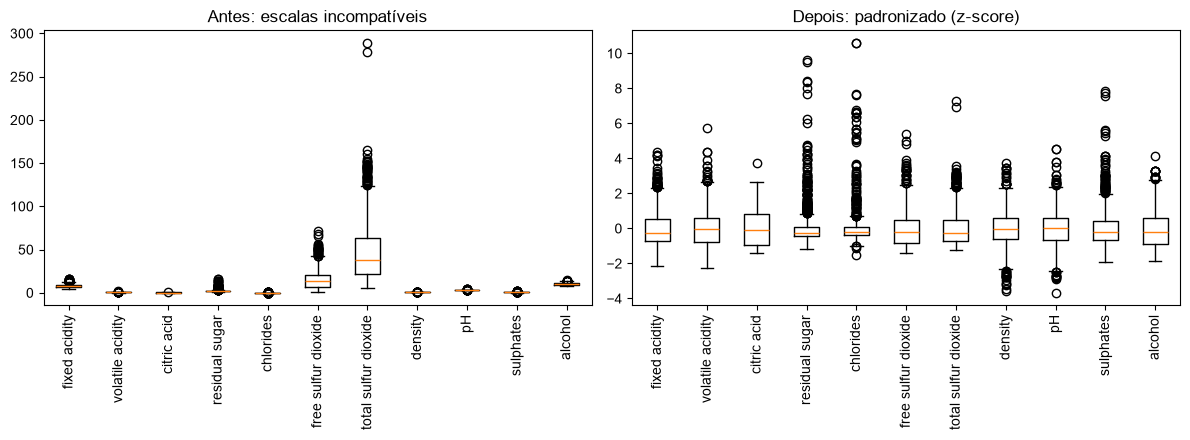

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].boxplot(X.values, tick_labels=X.columns)
ax[0].set_title("Antes: escalas incompatíveis")

ax[1].boxplot(StandardScaler().fit_transform(X), tick_labels=X.columns)
ax[1].set_title("Depois: padronizado (z-score)")

for a in ax:
    a.tick_params(axis="x", rotation=90)
    a.grid(False)
plt.tight_layout()
plt.savefig("figuras/boxplot_normalizacao.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Tarefa 2: Divisão Treino/Teste

Vamos dividir nosso *dataset* em treinamento (80%) e teste (20%), de forma **estratificada**, para que a proporção das três classes seja mantida nos dois conjuntos:

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]} amostras")
print(f"Teste:  {X_test.shape[0]} amostras")

display(pd.DataFrame({"treino": y_train.value_counts().reindex(ordem),
                      "teste": y_test.value_counts().reindex(ordem)}))

Treino: 1087 amostras
Teste:  272 amostras


,treino,teste
classe,,
ruim,512,128
médio,561,141
bom,14,3


Padronizando os atributos (a média e o desvio padrão são calculados apenas no treino):

In [12]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

Como referência, vamos calcular a acurácia de um classificador que sempre prevê a classe majoritária:

In [13]:
burro = DummyClassifier(strategy="most_frequent").fit(X_train_sc, y_train)
baseline = accuracy_score(y_test, burro.predict(X_test_sc))
print(f"Acurácia do classificador que sempre prevê a majoritária: {baseline:.4f}")

Acurácia do classificador que sempre prevê a majoritária: 0.5184


Verificando experimentalmente o efeito da normalização, com validação cruzada de 5 *folds* no treino e $k = 11$:

In [14]:
sem = cross_val_score(KNeighborsClassifier(n_neighbors=11), X_train, y_train, cv=5)
com = cross_val_score(KNeighborsClassifier(n_neighbors=11), X_train_sc, y_train, cv=5)

print(f"Sem normalização: {sem.mean():.4f} ± {sem.std():.4f}")
print(f"Com normalização: {com.mean():.4f} ± {com.std():.4f}")

Sem normalização: 0.6210 ± 0.0272
Com normalização: 0.6900 ± 0.0334


## 4. Tarefa 3: Treinamento e Escolha do $k$

Vamos treinar o $k$-NN para diferentes valores de $k$ utilizando validação cruzada de 5 *folds* sobre o conjunto de treino. Para enxergar o comportamento com $k$ muito alto, incluímos também valores grandes (até 801, perto do tamanho de cada partição de treino da validação cruzada, que tem cerca de 870 amostras). Também guardamos a acurácia no próprio treino, para comparar com a de validação:

In [15]:
valores_k = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 101, 201, 401, 801]
score_mean = np.zeros(len(valores_k))
score_std  = np.zeros(len(valores_k))
acc_treino = np.zeros(len(valores_k))

for idx, k in enumerate(valores_k):
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_sc, y_train, cv=5)
    score_mean[idx], score_std[idx] = scores.mean(), scores.std()
    acc_treino[idx] = accuracy_score(y_train, knn.fit(X_train_sc, y_train).predict(X_train_sc))
    print(f"k = {k:3d} | Acurácia (validação): {scores.mean():.4f} ± {scores.std():.4f} "
          f"| Acurácia (treino): {acc_treino[idx]:.4f}")

best_k = valores_k[np.argmax(score_mean)]
print(f"\nMelhor k = {best_k}")

k =   1 | Acurácia (validação): 0.6201 ± 0.0369 | Acurácia (treino): 1.0000
k =   3 | Acurácia (validação): 0.6458 ± 0.0217 | Acurácia (treino): 0.8188


k =   5 | Acurácia (validação): 0.6688 ± 0.0160 | Acurácia (treino): 0.7590
k =   7 | Acurácia (validação): 0.6688 ± 0.0151 | Acurácia (treino): 0.7479


k =   9 | Acurácia (validação): 0.6928 ± 0.0293 | Acurácia (treino): 0.7470


k =  11 | Acurácia (validação): 0.6900 ± 0.0334 | Acurácia (treino): 0.7387


k =  15 | Acurácia (validação): 0.6992 ± 0.0228 | Acurácia (treino): 0.7406
k =  21 | Acurácia (validação): 0.7011 ± 0.0326 | Acurácia (treino): 0.7397


k =  31 | Acurácia (validação): 0.7011 ± 0.0340 | Acurácia (treino): 0.7139
k =  51 | Acurácia (validação): 0.7075 ± 0.0354 | Acurácia (treino): 0.7259


k = 101 | Acurácia (validação): 0.7057 ± 0.0394 | Acurácia (treino): 0.7167


k = 201 | Acurácia (validação): 0.7075 ± 0.0372 | Acurácia (treino): 0.7121


k = 401 | Acurácia (validação): 0.7047 ± 0.0198 | Acurácia (treino): 0.7056


k = 801 | Acurácia (validação): 0.5161 ± 0.0025 | Acurácia (treino): 0.6633

Melhor k = 51


Plotando a acurácia média de validação em função de $k$:

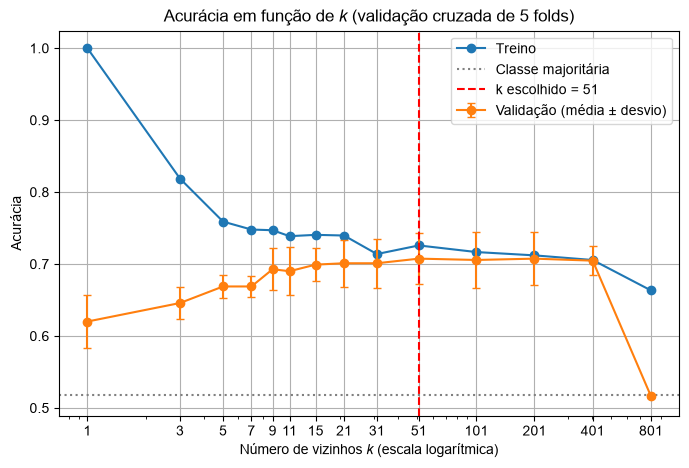

In [16]:
plt.plot(valores_k, acc_treino, marker="o", label="Treino")
plt.errorbar(valores_k, score_mean, yerr=score_std, marker="o", capsize=3,
             label="Validação (média ± desvio)")
plt.axhline(baseline, color="gray", linestyle=":", label="Classe majoritária")
plt.axvline(best_k, color="r", linestyle="--", label=f"k escolhido = {best_k}")
plt.xscale("log")
plt.xticks(valores_k, valores_k)
plt.xlabel("Número de vizinhos $k$ (escala logarítmica)")
plt.ylabel("Acurácia")
plt.title("Acurácia em função de $k$ (validação cruzada de 5 folds)")
plt.legend()
plt.grid()
plt.savefig("figuras/curva_k.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Tarefa 4: Avaliação do Modelo

Treinando o modelo final com o $k$ escolhido em todo o conjunto de treino e avaliando no conjunto de teste:

In [17]:
sklearn_knn = KNeighborsClassifier(n_neighbors=best_k)
sklearn_knn.fit(X_train_sc, y_train)

y_prev = sklearn_knn.predict(X_test_sc)
print(f"Acurácia: {accuracy_score(y_test, y_prev):.4f}")

Acurácia: 0.7206


A matriz de confusão (linhas = classe real, colunas = classe prevista) é:

            prev ruim  prev médio  prev bom
real ruim          84          44         0
real médio         29         112         0
real bom            0           3         0


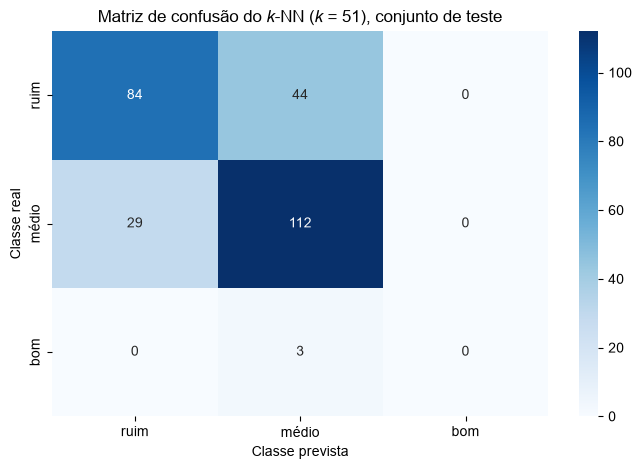

In [18]:
cm = confusion_matrix(y_test, y_prev, labels=ordem)
print(pd.DataFrame(cm, index=[f"real {c}" for c in ordem], columns=[f"prev {c}" for c in ordem]))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ordem, yticklabels=ordem)
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title(f"Matriz de confusão do $k$-NN ($k$ = {best_k}), conjunto de teste")
plt.savefig("figuras/matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

As métricas de precisão, *recall* e F1-*score* para cada classe:

In [19]:
print(classification_report(y_test, y_prev, labels=ordem, zero_division=0))

              precision    recall  f1-score   support

        ruim       0.74      0.66      0.70       128
       médio       0.70      0.79      0.75       141
         bom       0.00      0.00      0.00         3

    accuracy                           0.72       272
   macro avg       0.48      0.48      0.48       272
weighted avg       0.71      0.72      0.72       272



Contando os erros entre cada par de classes, para responder entre quais classes o modelo erra com mais frequência:

In [20]:
erros = []
for i, real in enumerate(ordem):
    for j, prev in enumerate(ordem):
        if i != j and cm[i, j] > 0:
            erros.append((f"{real} -> {prev}", cm[i, j]))

total_erros = cm.sum() - np.trace(cm)
for par, n in sorted(erros, key=lambda e: -e[1]):
    print(f"{par:15s}: {n:3d} ({100 * n / total_erros:.1f}% dos erros)")
print(f"\nTotal de erros: {total_erros}")

ruim -> médio  :  44 (57.9% dos erros)
médio -> ruim  :  29 (38.2% dos erros)
bom -> médio   :   3 (3.9% dos erros)

Total de erros: 76
